# Project Title: Olist Brazilian E-commerce Business Analysis

Executive Summary
This project provides a comprehensive business analysis of the Olist e-commerce dataset, covering over 100,000 orders and R$ 13.6 million in revenue. The analysis focuses on geographical revenue concentration, product category performance, payment method preferences, and the direct correlation between delivery performance and customer satisfaction. The findings reveal that while São Paulo is the primary revenue driver, smaller markets like Bahia demonstrate higher customer spending per order, suggesting diverse strategic opportunities. Furthermore, the analysis quantifies the severe negative impact of delivery delays on customer ratings, providing actionable data for operational improvement.

Importing the important libraries

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 

Loading Data

In [2]:
customer_details=pd.read_csv(r"C:\Users\DEEPANSHU JHA\OneDrive\Desktop\PROJECT FOLDERS\analysis\olist_customers_dataset.csv")
customer_details.sample(10)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
16666,3b1cbf321a120453df51216a651815af,9b4496ef27f4b987ed84d49a0386c28b,32240,contagem,MG
87876,0228874050786ca37c963d514a71684d,f475dc24f1a2e37576b20e8c23970543,11623,sao sebastiao,SP
27010,3b3a45b3d25deef9424d8d639366b795,c6e12d73878f91e2cc828da5da88663e,58150,pocinhos,PB
67354,67352448ce9cea9139d829803b4b824d,d56dfbcb10a4b7190345c1a2bc134fcb,79032,campo grande,MS
85724,3b59b8736180dfd0727518ab8c111985,cbb8cc3e9465a2b7078c72b2cd81536c,38425,uberlandia,MG
18764,dc0dff8cd3ed15ad2039e0bbe4982e42,13097c3575793a91362b51c3f942499d,8790,mogi das cruzes,SP
32157,a0dfd4423988ab0c24030a41e58774cd,fb0f84f881f307792ef22e8ac8f45f01,38300,ituiutaba,MG
755,d9a8e0bb4edbcd0ad3e059682ccb768e,a1b27fb279cf1f20c233f6f8c7d468ff,32115,contagem,MG
62358,db1c38264b085163dfd19679ddaf733e,13f2fe5bb99abcf24087665596fba59a,48120,pojuca,BA
45692,94203a446c1b46b5ac95b0aaf7221804,52a953541861bbb4b79b39df24e00243,13485,limeira,SP


In [3]:
customer_details.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


In [4]:
order=pd.read_csv(r"C:\Users\DEEPANSHU JHA\OneDrive\Desktop\PROJECT FOLDERS\analysis\olist_orders_dataset.csv")
order.sample(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
71849,8dd65fba2478cb614c25783cd1be3449,e2670ed9bc390629e358cf65e72fb1f5,delivered,2017-07-08 21:11:41,2017-07-08 21:25:15,2017-07-12 14:03:35,2017-07-17 19:18:27,2017-07-21 00:00:00
75958,81cedc4d2132eb6f512354166e51b187,a8f6bb35d78515a1762eb626d52b6352,delivered,2018-07-30 21:02:01,2018-07-30 21:10:20,2018-08-01 13:40:00,2018-08-07 19:11:43,2018-08-09 00:00:00
40234,5a9a959af722c04f7691c01c88736170,d7a16ce504fdfcb4c96e8bd0a8ff1a98,delivered,2018-01-08 11:01:30,2018-01-09 07:24:03,2018-01-10 12:35:34,2018-01-15 19:15:09,2018-01-31 00:00:00
72112,bfa5a8f656b7dc663c21308b0bc39212,30bf64b71d75305d57cc0d8bdeaaa92d,delivered,2017-11-07 01:07:57,2017-11-08 03:35:38,2017-11-08 18:57:47,2017-11-13 20:09:14,2017-11-28 00:00:00
11197,6c36ce692e5f1eac162de71b7e369805,60ec3b210180753924a4b3028b1f6b72,delivered,2017-07-25 23:16:48,2017-07-25 23:25:12,2017-07-26 20:22:06,2017-08-16 05:11:46,2017-08-24 00:00:00
14960,daf7a55aa310de14e9b2409edfedc2b4,a9e6b6a8984c388507d841184655052b,delivered,2018-07-21 16:42:24,2018-07-21 16:55:24,2018-08-13 14:26:00,2018-08-21 15:08:33,2018-09-03 00:00:00
84924,d66019cee9362dc5fb477e354c7cedf2,a2d6f67ddab4bf3f030cf1efcf214c7a,delivered,2017-05-19 09:08:04,2017-05-19 09:22:26,2017-05-19 12:59:27,2017-06-01 13:03:02,2017-06-21 00:00:00
52526,3224f9000ebffb83e1c48590824ba567,b515c26bc7955d05356ae832d2c4b54b,delivered,2018-03-02 16:12:57,2018-03-06 03:49:20,2018-03-06 23:48:50,2018-04-17 23:16:44,2018-03-21 00:00:00
70726,87889791f729ac3bc040d1633961d826,b4fea8b00d9af9605b5381e3100a0271,delivered,2018-08-20 18:17:43,2018-08-20 18:30:14,2018-08-22 14:27:00,2018-08-28 16:10:47,2018-09-04 00:00:00
15041,78cb9a560d2efd85da4adc637aab727f,fb51887c8244b5ca1d8f1f9e1b3bf4e7,delivered,2017-06-03 10:16:52,2017-06-06 13:35:33,2017-06-07 13:27:48,2017-06-19 16:32:27,2017-06-30 00:00:00


In [5]:
order.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [6]:
order_items=pd.read_csv(r"C:\Users\DEEPANSHU JHA\OneDrive\Desktop\PROJECT FOLDERS\analysis\olist_order_items_dataset.csv")
order_items.sample(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
91404,cf650037c918409bca8e5e67ee7dcfbe,1,d8f254be723da6488610b42935533b05,6560211a19b47992c3666cc44a7e94c0,2018-06-25 08:18:44,69.00,17.41
90264,cd02db25220d623f419da3b1fa2921ff,1,6b3de4cb14325f3a0dafa939520f514e,6560211a19b47992c3666cc44a7e94c0,2017-07-31 16:23:20,69.00,11.98
36951,53ec6e6945a5e805d1d8a58329b8e693,1,39a39074c35b5b8a466c85cf1d5b3387,35fb511489d9ee3ee27a76debce9df06,2018-02-26 22:08:07,35.00,17.92
68183,9bdc00acb04f677adc8329b932122fd6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-08-17 03:23:59,49.91,20.99
38550,57923ef279c2f7dacdb115f87a1f6c57,1,ba5fb4ab9cd70d201b74b5bad9d4ca00,562fc2f2c2863ab7e79a9e4388a58a14,2018-05-16 07:15:18,29.99,22.06
6158,0dfedf3d432d2cdca59a3ef16b313db6,1,2b4609f8948be18874494203496bc318,cc419e0650a3c5ba77189a1882b7556a,2017-10-20 04:28:18,89.99,35.95
55193,7d86c4aa9e59504b23f16c7ca68954a7,1,e8d7b12572b213ba22acebb8983a4615,8d92f3ea807b89465643c219455e7369,2017-01-31 16:38:10,63.90,26.71
64716,93d94474ff31149c751c5123897916d7,1,51ce083cd2b9078656a94655ab45b8a4,da8622b14eb17ae2831f4ac5b9dab84a,2018-06-04 13:51:06,199.90,25.55
11285,19b86ff7894bf15308ebd66e4158b236,1,c725d1884dc9fac3d9a4fb790c25da21,51702dc2a3e106c76dbff722b5bf0726,2017-05-05 08:15:35,169.90,18.48
85696,c2a3b4f6776c793ad0853b4076fda375,1,0b039b61011417822882815943f13dac,8b321bb669392f5163d04c59e235e066,2018-03-29 09:30:37,23.70,12.79


In [7]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


# State Analysis Section:

In [8]:
df1 = customer_details.merge(order, on="customer_id", how="inner")
print(f"After first join: {df1.shape}")

After first join: (99441, 12)


In [9]:
df2 = df1.merge(order_items, on="order_id", how="inner")
print(f"After second join: {df2.shape}")

After second join: (112650, 18)


In [10]:
revenue_by_state = df2.groupby('customer_state')['price'].sum().reset_index()
revenue_by_state = revenue_by_state.sort_values(by='price', ascending=False)
revenue_by_state

,customer_state,price
25,SP,5202955.05
18,RJ,1824092.67
10,MG,1585308.03
22,RS,750304.02
17,PR,683083.76
23,SC,520553.34
4,BA,511349.99
6,DF,302603.94
8,GO,294591.95
7,ES,275037.31


TOP 10 SATATES WITH THE HIGHEST REVENUE IS :

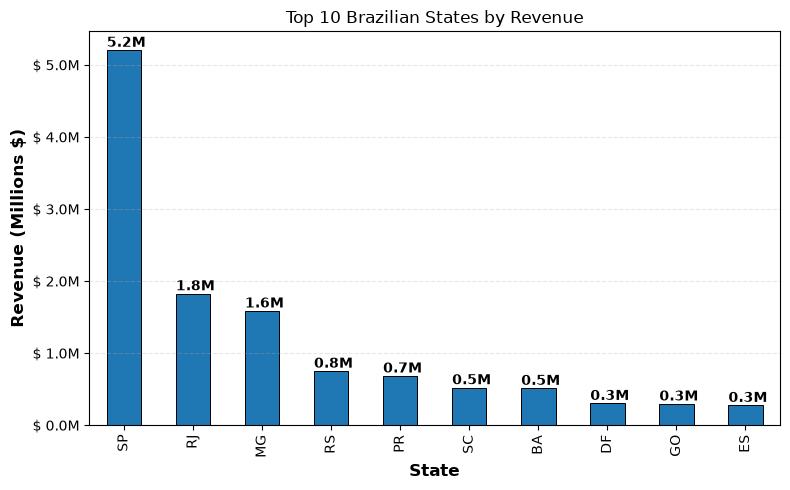

In [11]:
revenue_by_state.head(10).plot(kind='bar', x='customer_state', y='price', title='Top 10 Brazilian States by Revenue',  edgecolor='black', linewidth=0.7, legend=False, figsize=(8, 5))
ax = plt.gca()  # Get current axis
ax.yaxis.set_major_formatter(lambda x, p: f'$ {x / 1e6:.1f}M')

plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Revenue (Millions $)',fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# ADD VALUE LABELS ON TOP OF BARS
for bar in ax.patches:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f' {value / 1e6:.1f}M',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )
# Add this line before plt.show()
plt.savefig('revenue_by_state.png', dpi=300, bbox_inches='tight')
plt.show()

Top 3 states alone generate most of the revenue 

In [12]:
customer_perstate=df2.groupby('customer_state')['customer_unique_id'].nunique().reset_index().sort_values(by='customer_unique_id', ascending=False).head(10)
customer_perstate

,customer_state,customer_unique_id
25,SP,39981
18,RJ,12303
10,MG,11178
22,RS,5249
17,PR,4840
23,SC,3513
4,BA,3257
6,DF,2062
7,ES,1956
8,GO,1942


In [13]:
df2['revenue_per_customer'] = revenue_by_state['price'] / customer_perstate['customer_unique_id']

In [14]:
comparison = revenue_by_state.merge(customer_perstate, on='customer_state')
comparison = comparison.rename(columns={'price': 'Total_Revenue'})
comparison['Revenue_Per_Customer'] = (
    comparison['Total_Revenue'] / comparison['customer_unique_id']
)

comparison = comparison.sort_values(
    by='Revenue_Per_Customer', ascending=False
)
comparison = comparison.set_index('customer_state')

print(comparison.head(10))

                Total_Revenue  customer_unique_id  Revenue_Per_Customer
customer_state                                                         
BA                  511349.99                3257            157.000304
GO                  294591.95                1942            151.695134
RJ                 1824092.67               12303            148.264055
SC                  520553.34                3513            148.179146
DF                  302603.94                2062            146.752638
RS                  750304.02                5249            142.942279
MG                 1585308.03               11178            141.823943
PR                  683083.76                4840            141.133008
ES                  275037.31                1956            140.612122
SP                 5202955.05               39981            130.135691


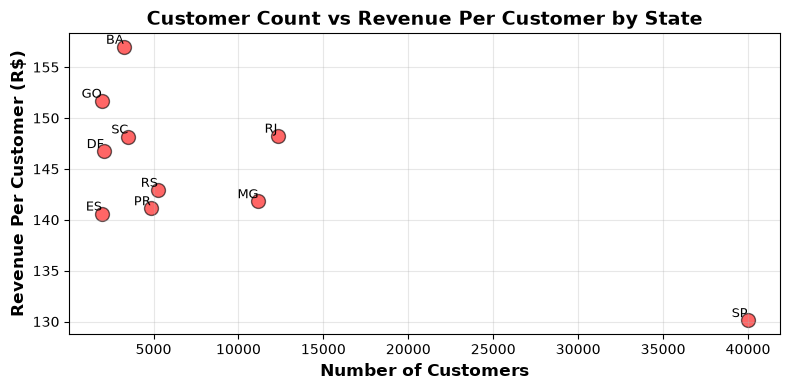

In [15]:

plt.figure(figsize=(8,4))

# Create scatter plot
plt.scatter(comparison['customer_unique_id'], 
            comparison['Revenue_Per_Customer'],
            s=100, alpha=0.6, color='red', edgecolor='black')

# Add state labels to each point
for idx, row in comparison.iterrows():
    plt.text(row['customer_unique_id'], 
             row['Revenue_Per_Customer'],
             idx,  # This is the state name
             fontsize=9, ha='right', va='bottom')

# Labels and title
plt.xlabel('Number of Customers', fontsize=12, fontweight='bold')
plt.ylabel('Revenue Per Customer (R$)', fontsize=12, fontweight='bold')
plt.title('Customer Count vs Revenue Per Customer by State', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('customer count vs revenue per customer.png', dpi=300, bbox_inches='tight')
plt.show()

###  Geographical Revenue Analysis
São Paulo (SP) is the dominant market, contributing 38% of total revenue. Interestingly, while SP leads in volume, states like Bahia (BA) exhibit higher revenue per customer, suggesting a premium customer segment that warrants a differentiated marketing strategy.

# Product Analysis Section:

In [16]:
product=pd.read_csv("olist_products_dataset.csv")
product.sample(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
4958,d58118713a21b8177e844c58eb83efe7,utilidades_domesticas,59.0,212.0,2.0,500.0,36.0,10.0,13.0
2416,82cef15a4bafa854c7a2a2c9854b7e44,perfumaria,58.0,1987.0,1.0,300.0,16.0,10.0,11.0
2282,97d27432ff43bde88266c3a3c42f4386,beleza_saude,51.0,1237.0,1.0,200.0,16.0,9.0,12.0
13879,b469675b10244fe989f232d3b38b41f4,cama_mesa_banho,48.0,289.0,1.0,1581.0,42.0,18.0,36.0
25194,b0c8da302d49498d2ce6be8c631e4e20,informatica_acessorios,24.0,401.0,1.0,213.0,18.0,12.0,13.0
22128,fadde2aec26938dd22add77b290d279d,utilidades_domesticas,57.0,614.0,1.0,4400.0,24.0,28.0,39.0
3636,29b65c78c1d8d70da25c6a553e1bfdb1,perfumaria,59.0,402.0,1.0,350.0,16.0,16.0,16.0
16626,a55d10eb698c768ef447648197bb0da9,cama_mesa_banho,57.0,214.0,1.0,1300.0,42.0,16.0,32.0
9181,9f05bf9bbb9b5629e674ce58804cd164,moveis_escritorio,34.0,1058.0,1.0,3125.0,45.0,55.0,16.0
22369,ed4dfdaab6c24770fc6f34ad50c89ac1,beleza_saude,53.0,269.0,5.0,250.0,16.0,15.0,15.0


In [17]:
translation=pd.read_csv("product_category_name_translation.csv")
translation.sample(10)

,product_category_name,product_category_name_english
70,seguros_e_servicos,security_and_services
4,moveis_decoracao,furniture_decor
21,fashion_calcados,fashion_shoes
56,eletrodomesticos_2,home_appliances_2
9,relogios_presentes,watches_gifts
50,fashion_underwear_e_moda_praia,fashion_underwear_beach
14,brinquedos,toys
37,agro_industria_e_comercio,agro_industry_and_commerce
3,cama_mesa_banho,bed_bath_table
20,audio,audio


For better understanding merge english translation 

In [18]:
df3 = product.merge(translation, on='product_category_name', how='left')
df3.sample(100)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
21083,4c2065301aac51ff9004422acc07765d,ferramentas_jardim,50.0,204.0,1.0,1663.0,36.0,14.0,27.0,garden_tools
29893,57c8519e414546bcd4311294c2eb4d85,moveis_escritorio,53.0,1084.0,1.0,30000.0,48.0,45.0,56.0,office_furniture
15036,2ec4063419591b373f7990da94fb2c6c,telefonia,44.0,375.0,2.0,50.0,20.0,20.0,20.0,telephony
611,c244b71b9f393724eaf2792a96427931,moveis_decoracao,59.0,589.0,1.0,400.0,17.0,8.0,17.0,furniture_decor
18028,a48138f7de6ebfed36f91a440fcadb64,esporte_lazer,49.0,1696.0,1.0,1800.0,31.0,36.0,31.0,sports_leisure
...,...,...,...,...,...,...,...,...,...,...
32028,417c36fe8603e10f20aba1359eb8e2f4,eletroportateis,51.0,2273.0,1.0,500.0,30.0,19.0,17.0,small_appliances
20303,f321a5d546506f8837f12d88408d9b77,esporte_lazer,48.0,683.0,1.0,875.0,19.0,19.0,19.0,sports_leisure
17856,c0b4f7401d69d6cf3de3b96e0f2ead2e,utilidades_domesticas,40.0,209.0,4.0,450.0,16.0,20.0,15.0,housewares
23554,678d94b37302bea8e20690b80838f239,automotivo,59.0,891.0,5.0,900.0,23.0,7.0,38.0,auto


In [19]:
df4 = df2.merge(df3, on='product_id', how='left')
df4 = df4.drop(columns=['revenue_per_customer'])
df4.sample(1000)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
41363,730769d8a5103f14d741ad1706e1c352,56181f89940ab3c08ebc6e7749ec6f3d,16300,penapolis,SP,b3981f7b203bb77c3d52bc97e46c5b25,delivered,2017-04-22 18:49:48,2017-04-22 19:01:19,2017-04-27 05:41:59,...,3.07,moveis_decoracao,43.0,3438.0,1.0,1000.0,41.0,23.0,25.0,furniture_decor
42382,ba922aa3fbd49b96cfece364f92bdb8b,6f64406ed5cfa4a2d9bd35e91bfd6587,81050,curitiba,PR,aad79b33466dbbe92bc7c1b9499ad365,delivered,2018-02-06 15:10:03,2018-02-06 16:11:38,2018-02-07 00:03:46,...,17.32,esporte_lazer,49.0,1313.0,1.0,2438.0,28.0,31.0,24.0,sports_leisure
5991,4f061e67c05a2736e7c07286ff3fa787,fded88a1576bd3a1383116738e43fb6c,71927,brasilia,DF,aa6bd33ba1853d846d3085a88ae37083,delivered,2018-08-10 21:36:37,2018-08-10 21:50:23,2018-08-13 15:18:00,...,15.24,fashion_bolsas_e_acessorios,36.0,352.0,3.0,150.0,16.0,9.0,11.0,fashion_bags_accessories
98368,5a01d03e70311e54445e9dc460e35c7a,777e39efdb2068331411db648c09d385,45990,teixeira de freitas,BA,02d5935847b855f189ad0391968773b2,delivered,2017-10-13 12:32:41,2017-10-13 12:49:09,2017-10-17 17:04:43,...,16.79,brinquedos,27.0,531.0,4.0,150.0,16.0,7.0,20.0,toys
13405,8a4097fca61c98661684fbfe703083ca,e5f42d1b1edc12b0594b446a57e35d5b,14795,colombia,SP,55af3f02d418fbfae46c0e04bffe4676,delivered,2017-10-04 12:47:40,2017-10-06 02:28:14,2017-10-10 20:35:41,...,12.19,tablets_impressao_imagem,56.0,512.0,1.0,300.0,26.0,10.0,26.0,tablets_printing_image
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97573,ef22056dc8495090cdc55992aa9ef1a5,c1ce726cce4f19c4aef436e4b78d319d,62550,morrinhos,CE,5a8badb776e5585c274fe19201012249,delivered,2018-03-07 21:02:00,2018-03-07 21:10:36,2018-03-13 01:03:06,...,37.04,beleza_saude,40.0,409.0,1.0,1110.0,19.0,11.0,18.0,health_beauty
25080,f9b4a5c4cad76c978b5c0192cebb8ff9,2b87c297be1f74435d51c1a602aa302f,15775,santa fe do sul,SP,f1bc2e9a22c1bd86a33e5f04595f1bdd,delivered,2018-06-21 09:49:21,2018-06-21 10:22:44,2018-06-26 15:00:00,...,27.58,beleza_saude,48.0,594.0,1.0,1850.0,24.0,36.0,23.0,health_beauty
17166,35ce0b4b731e2f576d0facbccab90b77,4d80869801d12dc0fd8492add2dbd7e6,32143,contagem,MG,93fd94c99b582fd7ccdf72b3721e34ea,delivered,2017-10-03 22:02:40,2017-10-06 09:56:18,2017-10-09 15:53:21,...,15.10,fashion_underwear_e_moda_praia,52.0,579.0,1.0,150.0,42.0,4.0,14.0,fashion_underwear_beach
80170,3afc42fd18017037f8a3972aa57c1436,a080513ac50b20c8e5b1cc046afe5fea,59124,natal,RN,88986b613097da641340bc366a2d91d4,delivered,2017-12-06 00:11:49,2017-12-08 15:52:51,2017-12-20 00:13:38,...,15.96,telefonia,57.0,523.0,1.0,400.0,23.0,6.0,15.0,telephony


In [ ]:
orders_product = (
    df4.groupby(['customer_state', 'product_category_name_english'])
       .agg(
           order_count=('order_id', 'nunique'),
           total_revenue=('price', 'sum')
       )
       .reset_index()
)

#  For EACH state, get top 3 categories
top_categories_per_state = (
    orders_product
    .sort_values('total_revenue', ascending=False)  # Sort by revenue
    .groupby('customer_state')                       # Group by state
    .head(3)                                         # Take top 3 from each group
)

top_categories_per_state.reset_index(drop=True, inplace=True)
top_categories_per_state

,customer_state,product_category_name_english,order_count,total_revenue
0,SP,bed_bath_table,4416,478284.52
1,SP,health_beauty,3789,462305.22
2,SP,watches_gifts,2135,435009.92
3,RJ,watches_gifts,817,185379.65
4,MG,health_beauty,1011,157558.30
...,...,...,...,...
76,AC,watches_gifts,4,1389.60
77,AC,health_beauty,6,1386.58
78,RR,sports_leisure,6,1350.60
79,RR,health_beauty,6,1050.61


In [ ]:
# sorting the companies 
state_order = ['SP', 'RJ', 'MG', 'RS', 'PR', 'BA', 'SC', 'DF', 'GO', 'ES']

# Convert customer_state to categorical with this order
top_categories_per_state['customer_state'] = pd.Categorical(
    top_categories_per_state['customer_state'],
    categories=state_order,
    ordered=True
)

# Now sort by this order
top_categories_sorted = top_categories_per_state.sort_values('customer_state')
top_categories_sorted.reset_index(drop=True, inplace=True)
top_categories_sorted.head(30)

C:\Users\DEEPANSHU JHA\AppData\Local\Temp\ipykernel_19304\2768977399.py:5: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  top_categories_per_state['customer_state'] = pd.Categorical(


,customer_state,product_category_name_english,order_count,total_revenue
0,SP,bed_bath_table,4416,478284.52
1,SP,health_beauty,3789,462305.22
2,SP,watches_gifts,2135,435009.92
3,RJ,watches_gifts,817,185379.65
4,RJ,bed_bath_table,1393,148035.23
5,RJ,health_beauty,974,145298.62
6,MG,health_beauty,1011,157558.30
7,MG,bed_bath_table,1129,129643.98
8,MG,watches_gifts,611,123759.23
9,RS,furniture_decor,444,54813.58


VISUALIZATION 

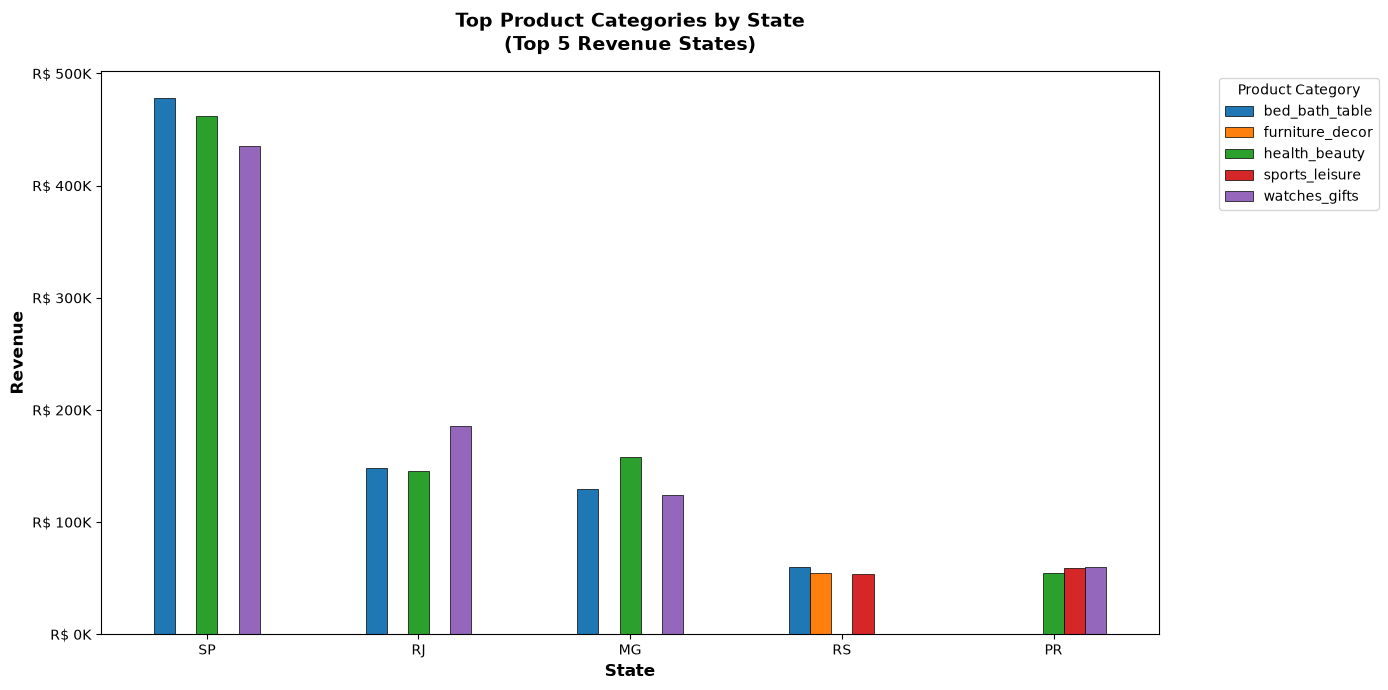

In [22]:
import matplotlib.pyplot as plt

# Step 1: Filter top 5 states
top_5_states = ['SP', 'RJ', 'MG', 'RS', 'PR']
chart1_data = top_categories_sorted[
    top_categories_sorted['customer_state'].isin(top_5_states)
]

# Step 2: Convert LONG to WIDE format using pivot_table
chart1_pivot = chart1_data.pivot_table(
    index='customer_state',      # Rows = States
    columns='product_category_name_english',  # Columns = Categories
    values='total_revenue',      # Values = Revenue
    aggfunc='sum'
).fillna(0)

# Step 3: Plot grouped bar chart
fig, ax = plt.subplots(figsize=(14, 7))
chart1_pivot.plot(kind='bar', ax=ax, edgecolor='black', linewidth=0.5)

# Step 4: Formatting
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'R$ {x/1000:.0f}K')
)
plt.title('Top Product Categories by State\n(Top 5 Revenue States)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Revenue', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(title='Product Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('product_categories_by_state.png', dpi=300, bbox_inches='tight')
plt.show()

To check in BA vs SP per customer expense does product play any role 

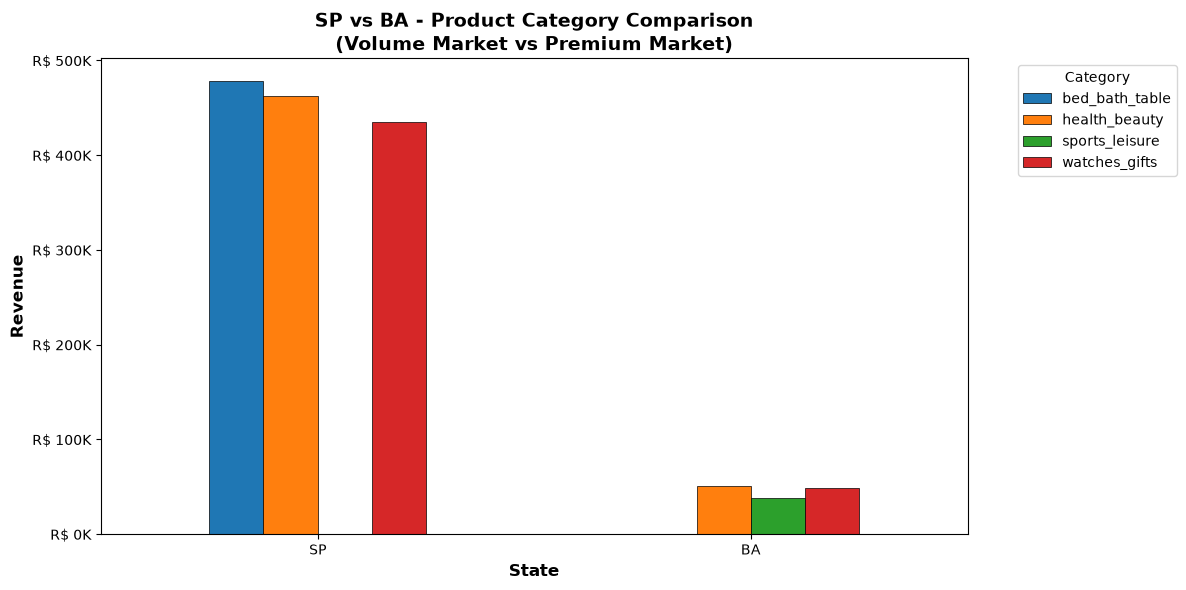

In [23]:
# Step 1: Filter only SP and BA
compare_data = top_categories_sorted[
    top_categories_sorted['customer_state'].isin(['SP', 'BA'])
]

# Step 2: Pivot
compare_pivot = compare_data.pivot_table(
    index='customer_state',
    columns='product_category_name_english',
    values='total_revenue',
    aggfunc='sum'
).fillna(0)

# Step 3: Plot
fig, ax = plt.subplots(figsize=(12, 6))
compare_pivot.plot(kind='bar', ax=ax, edgecolor='black', linewidth=0.5)

# Step 4: Formatting
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'R$ {x/1000:.0f}K')
)
plt.title('SP vs BA - Product Category Comparison\n(Volume Market vs Premium Market)', 
          fontsize=14, fontweight='bold')
plt.xlabel('State', fontsize=12, fontweight='bold')
plt.ylabel('Revenue', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('sp_vs_ba_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

###  Product Category Preferences
The analysis of product categories reveals that bed_bath_table, health_beauty, and watches_gifts are the core revenue drivers across the board. The consistency of these top-performing categories indicates a stable product-market fit across Brazil.

# Time Analysis Section

In [24]:
order.sample(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
45033,9439142ac9f68b5cfaa4bbd1e2052ba0,2a0ffe70fa6ad3911b6b1d9e3c9af7c6,delivered,2018-05-04 08:41:06,2018-05-04 08:55:26,2018-05-10 14:26:00,2018-05-22 19:50:56,2018-06-01 00:00:00
59113,5ec0629d25d2736b943c5607137c5182,024d9375532751f84d5bb83ac936b3f8,delivered,2018-06-23 12:14:03,2018-06-23 12:34:56,2018-06-26 14:13:00,2018-07-02 18:50:59,2018-07-17 00:00:00
64421,266c2a7993cdd7ceb3422646db5f4ea2,09566707b6df407df83b88ae3c1f5ffd,delivered,2018-01-09 14:34:36,2018-01-09 14:50:15,2018-01-11 19:48:57,2018-01-15 18:22:01,2018-01-26 00:00:00
96207,c2b1c0fcdd5d03ed47f2b02494cdbc63,78078075e327093313db151ad0db0e38,delivered,2017-11-30 13:31:19,2017-11-30 13:52:17,2017-11-30 23:16:46,2017-12-12 20:58:50,2017-12-28 00:00:00
45759,083dcf8ec0ff8aedc0d7ad8063baad80,80f48bf1d049cdecddea8ea5086b1264,delivered,2018-04-19 12:06:09,2018-04-19 12:33:16,2018-04-19 22:15:47,2018-05-03 12:52:04,2018-05-14 00:00:00
9118,1ea11b975aea60ca92fa0559184d3d34,0d1679b303ad5d2c0cb3e51bc9c9f643,delivered,2017-03-30 23:04:33,2017-03-30 23:22:38,2017-05-17 11:23:54,2017-05-20 09:32:55,2017-05-31 00:00:00
29662,166a835dcb0ffdb5d917db2a93358502,3274aedc859b9aa7d7e5db28cfb7768d,delivered,2017-07-11 23:14:57,2017-07-11 23:25:18,2017-07-13 19:09:52,2017-07-31 11:34:32,2017-08-04 00:00:00
313,6379750dac6a8a1e11378e34278ae8df,6729078b4efa4371e61e6ec7df327846,delivered,2017-09-11 11:50:32,2017-09-11 12:05:28,2017-09-14 20:57:27,2017-09-19 21:47:09,2017-10-04 00:00:00
93776,29182856a24c6eeb1d7b81ba1fe63190,e13dd3f5bb12b741263db05564de3f13,delivered,2017-07-20 16:52:06,2017-07-20 17:05:16,2017-07-21 12:39:28,2017-07-29 15:04:38,2017-08-11 00:00:00
82032,b7e65c7d814aa068f3b16bf2a1299490,2896fdb188d66ea9a9118e5c7cb62ec3,delivered,2018-07-25 23:36:12,2018-07-26 23:30:08,2018-07-27 14:53:00,2018-08-01 18:48:54,2018-08-13 00:00:00


In [25]:
# Filter delivered orders
order_delivered = order[order['order_status'] == 'delivered']

# Convert timestamp (store back in dataframe)
order_delivered['order_purchase_timestamp'] = pd.to_datetime(
    order_delivered['order_purchase_timestamp']
)

# Extract month and year from purchase timestamp
order_delivered['month'] = order_delivered['order_purchase_timestamp'].dt.month
order_delivered['year'] = order_delivered['order_purchase_timestamp'].dt.year
order_delivered.sample(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,year
82886,666ede5bf7b6eebd0d2f61795ee14149,abad8dba5de22702ed59246b0f2455b7,delivered,2018-07-04 10:06:56,2018-07-05 16:31:46,2018-07-05 14:02:00,2018-07-07 12:38:26,2018-07-31 00:00:00,7,2018
49145,6041df98b73499d7ab29fac08814665b,87f2c343f1205c2e07e58c9b3a755444,delivered,2017-12-31 10:30:34,2017-12-31 10:39:26,2018-01-03 17:16:22,2018-01-19 23:08:52,2018-01-26 00:00:00,12,2017
2326,a88fb9a6e45cb10ebd5ebac6846d1ecf,cd3ce27aac0c6ecc4a3ca29a93f07c51,delivered,2018-01-01 18:56:38,2018-01-01 19:05:29,2018-01-05 17:15:38,2018-01-11 21:37:09,2018-02-21 00:00:00,1,2018
86719,e49e382e440b76f65be6ce311948835c,0971df83869ecd83b4282f773573bff3,delivered,2018-06-10 18:05:07,2018-06-10 19:38:14,2018-06-11 15:53:00,2018-06-15 18:58:36,2018-07-05 00:00:00,6,2018
71437,0a84b71d2fd93eeae49d3149a3e08003,f21fdacae3273ac85cc6e33919cae43a,delivered,2017-11-28 21:47:50,2017-12-01 10:31:42,2017-12-01 21:12:14,2018-01-09 18:28:48,2017-12-19 00:00:00,11,2017
61510,26d26e749356ec5a267c065241ea05e7,3d4468ce8d2cbae5ded23093c9e039e2,delivered,2018-03-06 11:03:36,2018-03-06 11:15:52,2018-03-07 22:13:31,2018-04-04 22:04:51,2018-04-09 00:00:00,3,2018
5690,5d025adca7f94a2bdfd06c914a9bc601,16b792424429f7c1c708a83acba00014,delivered,2017-10-12 02:31:17,2017-10-12 03:20:13,2017-10-13 22:53:40,2017-10-17 18:28:45,2017-10-25 00:00:00,10,2017
10154,51e5e08365469f68d9f281c619b2354f,4c6ee863183b6981c871a3e8b75bce29,delivered,2018-08-04 15:27:00,2018-08-07 04:45:21,2018-08-07 13:53:00,2018-08-14 12:36:58,2018-08-28 00:00:00,8,2018
49299,5ff78652a040431e007c9349249d3503,c0a599a259226219c1ea0d3b8821ca54,delivered,2018-04-22 20:52:20,2018-04-24 19:00:48,2018-04-24 22:28:44,2018-04-30 18:56:37,2018-05-16 00:00:00,4,2018
70808,f001d39de25ce801a4b275f5ad3e1c2e,12b911aa1a2831e2ee7c2e5eaf03bedc,delivered,2017-11-24 20:57:27,2017-11-25 00:31:33,2017-11-27 12:33:20,2018-01-04 00:18:36,2017-12-19 00:00:00,11,2017


In [27]:
df5=order_delivered.merge(order_items, on='order_id', how='inner')   
df5.sample(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,year,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
69291,43b68bc17b7182a73f19829a1cbd4333,8f65470a3b714b3a99454dc4cf3610e8,delivered,2018-01-30 15:55:22,2018-01-30 16:12:52,2018-01-31 18:04:51,2018-02-25 10:35:08,2018-03-01 00:00:00,1,2018,2,6002665d65ee348dcd357c7bb2f080bd,f45122a9ab94eb4f3f8953578bc0c560,2018-02-05 16:12:52,59.99,15.26
65828,bcb9cb204fb7137dcb5dc3fdb94f11e5,75ecb22a47dc997aad56a99f05c74c49,delivered,2017-07-17 19:27:39,2017-07-17 19:43:01,2017-07-18 19:15:49,2017-07-19 19:57:30,2017-07-31 00:00:00,7,2017,1,9ebfbbb1a5a173f758cb76d6ecc75f9b,d12c926d74ceff0a90a21184466ce161,2017-07-24 19:43:01,21.50,7.78
24123,50182b772092990f9c237c00c8c24996,d9bda6cddcb5b6018967ef7e142e9965,delivered,2017-07-19 20:24:58,2017-07-21 02:55:24,2017-07-26 15:53:51,2017-07-27 17:46:25,2017-08-01 00:00:00,7,2017,1,c6336fa91fbd87c359e44f5dca5a90ed,4c2b230173bb36f9b240f2b8ac11786e,2017-07-27 02:55:24,39.90,8.72
84080,efcd8852328a37fca811747c09c6fb69,1471498aaeb8618816b95071d851da29,delivered,2017-05-21 08:01:40,2017-05-22 10:39:14,2017-05-22 12:48:50,2017-05-24 15:05:49,2017-06-02 00:00:00,5,2017,2,cf8c83ef74f69705d1bec196473b1b45,520b493b57809f446cb0a233bb3e25c7,2017-05-25 09:31:35,20.00,9.94
102191,c583d1e4fd69999ff69ba3b41639434c,32900c3c8bb35455d2ae421e3556b479,delivered,2018-03-12 16:55:53,2018-03-13 03:50:32,2018-03-13 20:03:53,2018-04-02 14:30:10,2018-04-03 00:00:00,3,2018,1,c15c05beb23ff0f89b50e98c810dbc03,febab0275244b9a49a623f0bd613ca2f,2018-03-19 03:50:32,29.90,16.32
49749,adb8748f912cfee84bd47f072681ba5e,2f37ca7ce30fbfaf6cf6eea538fa754b,delivered,2017-05-05 16:54:28,2017-05-05 17:05:14,2017-05-09 17:01:21,2017-05-11 15:55:58,2017-06-01 00:00:00,5,2017,1,85f1c33512bb37126e995ddf7de34cb9,744dac408745240a2c2528fb1b6028f3,2017-05-11 17:05:14,178.00,16.95
14719,843fae0263cbfc12d1126522fb216aa7,17bbadf6276485131a966dde427de51e,delivered,2018-03-27 10:03:17,2018-03-27 10:15:21,2018-03-29 17:45:02,2018-04-02 16:12:24,2018-04-09 00:00:00,3,2018,1,19421075ae0b585f2dc13ff149e2119d,4c2b230173bb36f9b240f2b8ac11786e,2018-04-02 10:15:21,49.90,7.39
106778,aa94d94e210dc2b7a49812d3d82bb516,f0c661c3c1e7d42a43f9ac9db2619c6c,delivered,2017-11-07 10:19:53,2017-11-07 10:30:58,2017-11-07 17:13:36,2017-11-10 19:19:46,2017-11-27 00:00:00,11,2017,2,d6d73c1fe2e8c0e3e90e2421ffa4b963,01c97ebb5cdac52891c0ed1c37ba0012,2017-11-13 10:30:38,29.40,12.69
83009,33dbd2002d80438989cc32296d1a2ed9,7349bc741ff5280290064d08ecf1eb62,delivered,2017-10-21 17:56:41,2017-10-21 18:14:17,2017-10-26 21:58:37,2017-10-27 17:44:01,2017-11-08 00:00:00,10,2017,2,446e83f3f31931e9eda31363bde07293,5058e8c1e82653974541e83690655b4a,2017-10-31 18:14:17,24.99,15.28
106684,a72fc5669df669ab2c501cd323698fac,05ad4097a892d5d8163107dd0bc3ca2d,delivered,2018-02-27 21:15:55,2018-02-28 12:50:25,2018-03-02 17:17:05,2018-05-12 19:38:34,2018-04-13 00:00:00,2,2018,1,4328139cbe9adde0aac493ca9871eab3,8160255418d5aaa7dbdc9f4c64ebda44,2018-03-06 12:50:25,69.90,47.02


In [28]:
df5.groupby(['year', 'month'])
monthly_revenue = (
    df5.groupby(["year", "month"], as_index=False)
       .agg(total_revenue=("price", "sum"))
       .sort_values(["year", "month"])
)

monthly_revenue


,year,month,total_revenue
0,2016,9,134.97
1,2016,10,40325.11
2,2016,12,10.90
3,2017,1,111798.36
4,2017,2,234223.40
5,2017,3,359198.85
6,2017,4,340669.68
7,2017,5,489338.25
8,2017,6,421923.37
9,2017,7,481604.52


In [29]:
df5.groupby(['year'])
annual_revenue=(
    df5.groupby(['year'] , as_index=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values(by='year')
)

annual_revenue

,year,total_revenue
0,2016,40470.98
1,2017,5962902.01
2,2018,7218125.12


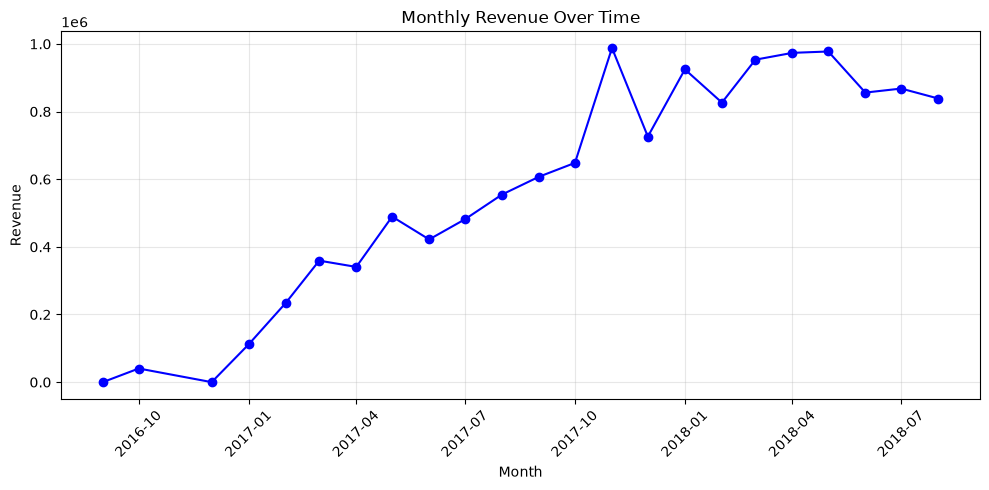

In [30]:
# Create a temporary dataframe
df_plot = monthly_revenue.copy()
# Convert year and month to string first
df_plot['date'] = df_plot['year'].astype(str) + '-' + df_plot['month'].astype(str)

# 2. Convert that string to a real datetime object
df_plot['date'] = pd.to_datetime(df_plot['date'])

plt.plot(df_plot['date'], df_plot['total_revenue'],
         marker='o', color='b', label='Monthly Revenue')
plt.title('Monthly Revenue Over Time')
plt.gcf().set_size_inches(10, 5)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

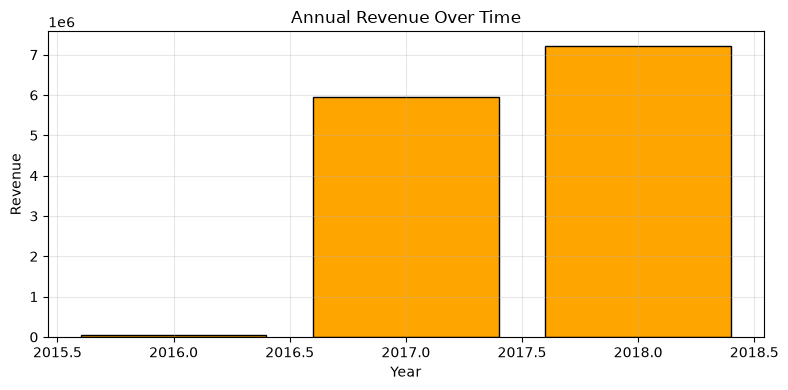

In [31]:
plt.bar(annual_revenue['year'], annual_revenue['total_revenue'], color='orange', edgecolor='black')
plt.title('Annual Revenue Over Time')
plt.gcf().set_size_inches(8, 4)
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('annual_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()


### Temporal Revenue Trends
The analysis of annual and monthly revenue trends indicates strong positive growth from 2016 through 2018. Month-over-month analysis shows significant revenue spikes, suggesting strong seasonal purchasing patterns. This trend data is vital for inventory planning and optimizing marketing spend during peak sales periods.

# Payment Analysis Section:

In [32]:
payment = pd.read_csv("olist_order_payments_dataset.csv")
payment.head(20)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


In [33]:
payment_analysis = payment.groupby('payment_type').agg(
    total_revenue=('payment_value', 'sum'),
    order_count=('order_id', 'nunique')
).sort_values(by='total_revenue', ascending=False).reset_index()
payment_analysis

,payment_type,total_revenue,order_count
0,credit_card,12542084.19,76505
1,boleto,2869361.27,19784
2,voucher,379436.87,3866
3,debit_card,217989.79,1528
4,not_defined,0.00,3


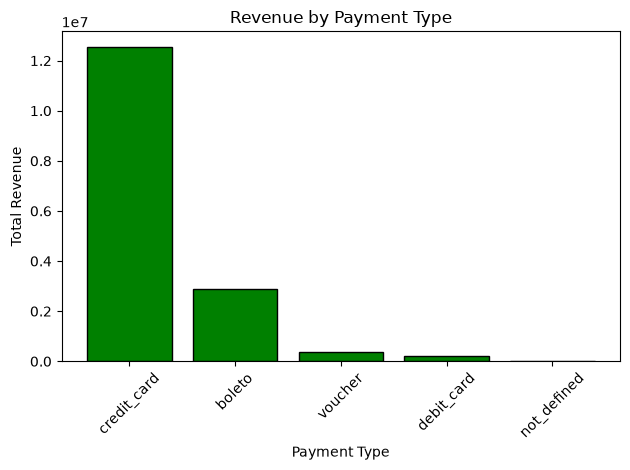

In [34]:
plt.bar(payment_analysis['payment_type'], payment_analysis['total_revenue'], color='green', edgecolor='black')
plt.title('Revenue by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('revenue_by_payment_type.png', dpi=300, bbox_inches='tight')
plt.show()

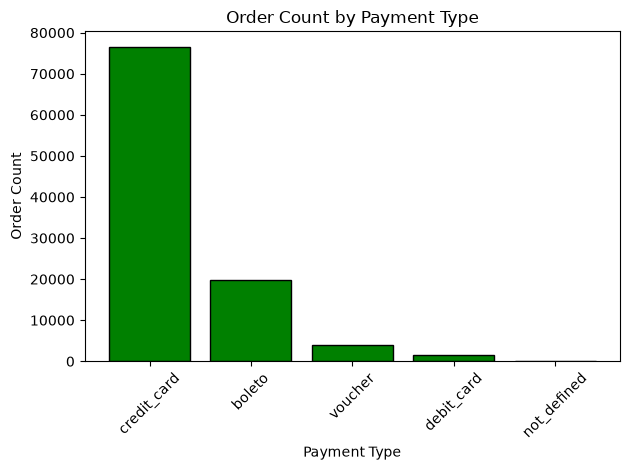

In [35]:
plt.bar(payment_analysis['payment_type'], payment_analysis['order_count'], color='green', edgecolor='black')
plt.title('Order Count by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Order Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('order_count_by_payment_type.png', dpi=300, bbox_inches='tight')
plt.show()

###  Payment Method Insights
Credit cards are the primary payment method for the vast majority of transactions. This insight suggests that the company’s operational focus should be on ensuring high-availability and security for credit card processing, as any disruption here would disproportionately impact revenue.

# Delivery Analysis Section :

In [36]:
review = pd.read_csv("olist_order_reviews_dataset.csv")

In [37]:
delivery=order_delivered.merge(review, on='order_id', how='inner')
delivery.reset_index(drop=True, inplace=True)
delivery

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,year,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,10,2017,a54f0611adc9ed256b57ede6b6eb5114,4,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,7,2018,8d5266042046a06655c8db133d120ba5,4,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,8,2018,e73b67b67587f7644d5bd1a52deb1b01,5,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,11,2017,359d03e676b3c069f62cadba8dd3f6e8,5,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2,2018,e50934924e227544ba8246aeb3770dd4,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96356,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,3,2017,e262b3f92d1ce917aa412a9406cf61a6,5,NaN,NaN,2017-03-22 00:00:00,2017-03-23 11:02:08
96357,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,2,2018,29bb71b2760d0f876dfa178a76bc4734,4,NaN,So uma peça que veio rachado mas tudo bem rs,2018-03-01 00:00:00,2018-03-02 17:50:01
96358,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,8,2017,371579771219f6db2d830d50805977bb,5,NaN,Foi entregue antes do prazo.,2017-09-22 00:00:00,2017-09-22 23:10:57
96359,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1,2018,8ab6855b9fe9b812cd03a480a25058a1,2,NaN,Foi entregue somente 1. Quero saber do outro p...,2018-01-26 00:00:00,2018-01-27 09:16:56


In [38]:
delivery['order_delivered_customer_date'] = pd.to_datetime(delivery['order_delivered_customer_date'])
delivery['order_estimated_delivery_date'] = pd.to_datetime(delivery['order_estimated_delivery_date'])
delivery.info()

<class 'pandas.DataFrame'>
RangeIndex: 96361 entries, 0 to 96360
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96361 non-null  str           
 1   customer_id                    96361 non-null  str           
 2   order_status                   96361 non-null  str           
 3   order_purchase_timestamp       96361 non-null  datetime64[us]
 4   order_approved_at              96347 non-null  str           
 5   order_delivered_carrier_date   96359 non-null  str           
 6   order_delivered_customer_date  96353 non-null  datetime64[us]
 7   order_estimated_delivery_date  96361 non-null  datetime64[us]
 8   month                          96361 non-null  int32         
 9   year                           96361 non-null  int32         
 10  review_id                      96361 non-null  str           
 11  review_score              

In [39]:
delivery['is_late'] = delivery['order_delivered_customer_date'] - delivery['order_estimated_delivery_date']
# we only fletch out days so we can analyze the delay in days
delivery['delay_days'] = delivery['is_late'].dt.days
# convert days into a categorical variable for better visualization
delivery['is_late'] = delivery['delay_days'].apply(lambda x: 'Late' if x > 0 else 'On Time')

In [40]:
# Group by the 'is_late' flag and calculate the mean of 'review_score'
review_impact = delivery.groupby('is_late')['review_score'].mean()
print(review_impact)

is_late
Late       2.271025
On Time    4.289999
Name: review_score, dtype: float64


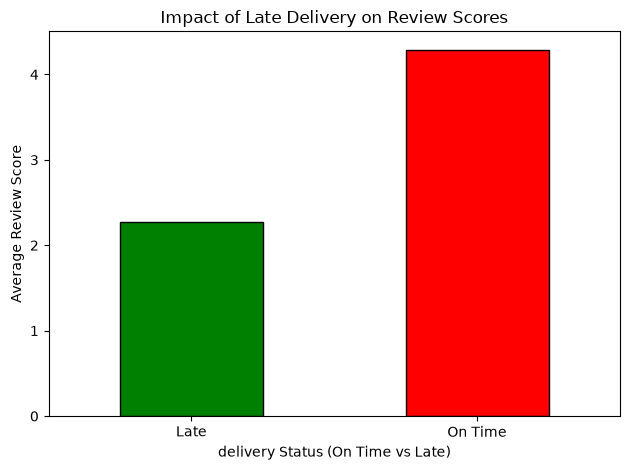

In [41]:
# Simple plot of review_impact
review_impact.plot(kind='bar', color=['green', 'red'], edgecolor='black')
plt.title('Impact of Late Delivery on Review Scores')
plt.xlabel('delivery Status (On Time vs Late)')
plt.ylabel('Average Review Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('impact_of_late_delivery_on_review_scores.png', dpi=300, bbox_inches='tight')
plt.show()

In [42]:
# Create bins for delay duration
bins = [-100, 0, 3, 7, 14, 30, 365]
labels = ['Early/On-Time', '1-3 Days', '4-7 Days', '8-14 Days', '15-30 Days', '30+ Days']

delivery['delay_category'] = pd.cut(delivery['delay_days'], bins=bins, labels=labels)

# Group by these new categories and get the average review score
delay_impact = delivery.groupby('delay_category')['review_score'].mean()
print(delay_impact)

delay_category
Early/On-Time    4.289963
1-3 Days         3.289871
4-7 Days         2.104214
8-14 Days        1.676309
15-30 Days       1.617357
30+ Days         2.054381
Name: review_score, dtype: float64


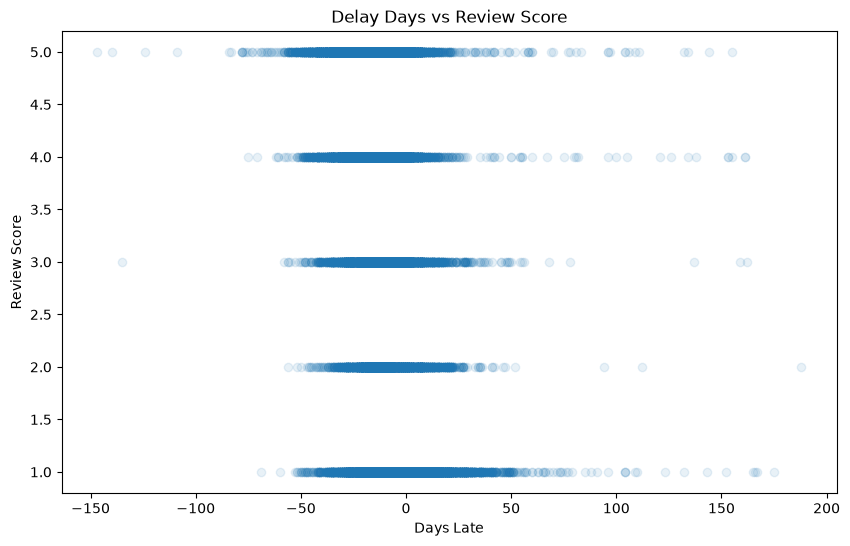

In [45]:
plt.figure(figsize=(10,6))
plt.scatter(delivery['delay_days'], delivery['review_score'], alpha=0.1)
plt.title('Delay Days vs Review Score')
plt.xlabel('Days Late')
plt.ylabel('Review Score')
plt.savefig("DelayDays_vs_Review.png", dpi=300, bbox_inches='tight')
plt.show()

###  Operational Impact on Customer Satisfaction
This analysis confirms a direct correlation between delivery performance and customer sentiment. Late deliveries result in a dramatic decrease in average review scores, dropping from 4.29 for on-time deliveries to 2.27 for late arrivals. This quantitative evidence highlights the critical need to optimize logistics to maintain customer loyalty.